# 🎨 Food Colorant QC — Colorimetry, SPC & Early-Warning Models

**Context.** In a food-colorant plant, a batch is released only if it matches the *standard* in **colour** (CIELAB, ΔE), **strength**, **moisture** and **contaminants** (e.g. lead). Colour is measured by a spectrophotometer, compared with the standard, and a QC chemist decides: *release*, *rework (shade correction)* or *reject*.

This notebook turns a raw LIMS-style export into answers to the questions a QC manager actually asks:

| # | Question | Technique |
|---|---|---|
| 1 | Is the export trustworthy? | audit + cleaning (incl. results below the limit of quantification) |
| 2 | How far is each batch from the standard colour, and in which direction? | CIELAB, **CIEDE2000 (ΔE00)**, ΔL\*/Δa\*/Δb\* shade direction |
| 3 | Is the process stable and capable? | **SPC control charts** (I-chart, Nelson run rule), **Cp / Cpk**, Pareto of non-conformances |
| 4 | What causes off-shade batches? | supplier / shift / line comparison, rank correlations, statistical tests |
| 5 | Can we flag likely off-shade batches **before** the lab result arrives? | regression of ΔE00 and classification of "out of tolerance" from *process data only*, time-ordered validation |
| 6 | Do the recorded release decisions follow the spec? | rule-based audit of decisions |

> ⚠️ **About the data.** There is no public Kaggle dataset of food-colorant batch QC, and real plant data is confidential.
> This notebook runs on a **simulated LIMS-style export** (`generate_colorant_data.py`) whose structure follows what a plant typically exports.
> The standard colours, process targets, spec limits and effect sizes are **illustrative assumptions — not measurements from any real plant**,
> and every conclusion below is a conclusion about *that simulated process*.
> To use real data: export your own (anonymised, and rescaled if needed) batches to `data/colorant_batches.csv` with the same column names,
> adjust the `SPEC` / `STANDARD_LAB` / `PROCESS_TARGETS` blocks in the setup cell, and *Restart & Run All*.

**Tolerance note.** Published guidance for ΔE tolerances varies by product and customer: vendor material cites about 1.5 for clear desserts/beverages and up to about 3 for general food & beverage applications. This notebook uses **ΔE00 ≤ 1.5** as an illustrative internal limit.

## 0. Setup and specifications

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
import joblib

from colorimetry import ciede2000          # CIEDE2000 implementation (see colorimetry.py)

RANDOM_STATE = 42
DATA_PATH = "data/colorant_batches.csv"

# ---- ILLUSTRATIVE specifications: replace with your product specs / customer / regulatory limits ----
SPEC = dict(dE_max=1.5,                       # max colour difference vs standard (CIEDE2000)
            strength_lo=95.0, strength_hi=105.0,   # tinctorial strength, % of standard
            strength_reject=92.0,             # below this the batch cannot be reworked
            moisture_max=6.0,                 # % (powders)
            lead_max=2.0)                     # ppm (mg/kg)
LOQ_LEAD = 0.1                                # limit of quantification of the lead method (ppm)

# colour of the standard (L*, a*, b*) per product - illustrative values
STANDARD_LAB = {"Yellow_Synthetic": (87.0, -4.0, 82.0), "Red_Synthetic": (42.0, 66.0, 38.0),
                "Blue_Synthetic": (28.0, -8.0, -52.0), "Orange_Natural": (68.0, 38.0, 72.0)}
# SOP targets per product: (reaction temperature C, final pH) - illustrative
PROCESS_TARGETS = {"Yellow_Synthetic": (65.0, 7.0), "Red_Synthetic": (70.0, 6.5),
                   "Blue_Synthetic": (60.0, 7.2), "Orange_Natural": (55.0, 5.5)}
MIX_MIN_SOP, DRY_MAX_SOP = 38.0, 88.0         # minimum mixing time (min), maximum drying temperature (C)

PRODUCT_COLORS = {"Yellow_Synthetic": "#E8B923", "Red_Synthetic": "#C0392B",
                  "Blue_Synthetic": "#2E6F95", "Orange_Natural": "#E67E22"}
TEAL, RED, GREY, GREEN = "#1F7A8C", "#C0392B", "#6B7280", "#2F7D4F"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
print("pandas", pd.__version__, "| numpy", np.__version__)

Matplotlib is building the font cache; this may take a moment.


pandas 3.1.0 | numpy 2.5.4


## 1. Load and audit the raw export

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (1519, 19)


,Batch_ID,Date,Product,Form,Line,Shift,Supplier,Batch_Size_kg,Reaction_Temp_C,pH_Final,Mixing_Time_min,Drying_Temp_C,L,a,b,Strength_pct,Moisture_pct,Lead_ppm,Release_Decision
0,CL24665,2024-08-23,Blue_Synthetic,Liquid,Line-1,Afternoon,C,1000.0,59.2,7.14,52.0,NaN,26.68,-7.58,-52.56,97.8,NaN,0.395,Release
1,CL25096,2025-01-30,Red_Synthetic,Powder,Line-3,Afternoon,B,500.0,70.3,6.57,57.0,87.1,41.74,65.66,37.86,100.1,3.01,0.2,Release
2,CL24334,2024-04-20,Red_Synthetic,Liquid,Line-3,Morning,B,500.0,67.4,6.46,48.0,NaN,42.86,64.47,36.91,98.6,NaN,0.431,Release
3,CL24253,2024-03-26,Orange_Natural,Liquid,Line-1,Afternoon,A,1000.0,54.5,5.51,53.0,NaN,68.48,38.71,71.07,97.9,NaN,0.191,Release
4,CL25169,2025-02-27,Orange_Natural,Liquid,Line-2,Afternoon,A,1000.0,57.7,5.56,33.0,NaN,67.68,37.06,68.57,96.6,NaN,<0.1,Release


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1519 entries, 0 to 1518
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Batch_ID          1519 non-null   str    
 1   Date              1518 non-null   str    
 2   Product           1518 non-null   str    
 3   Form              1518 non-null   str    
 4   Line              1518 non-null   str    
 5   Shift             1518 non-null   str    
 6   Supplier          1518 non-null   str    
 7   Batch_Size_kg     1518 non-null   float64
 8   Reaction_Temp_C   1506 non-null   float64
 9   pH_Final          1503 non-null   float64
 10  Mixing_Time_min   1501 non-null   float64
 11  Drying_Temp_C     751 non-null    float64
 12  L                 1501 non-null   str    
 13  a                 1507 non-null   str    
 14  b                 1509 non-null   str    
 15  Strength_pct      1507 non-null   str    
 16  Moisture_pct      751 non-null    float64
 17  Lead_p

In [4]:
NUM_COLS = ["Batch_Size_kg", "Reaction_Temp_C", "pH_Final", "Mixing_Time_min", "Drying_Temp_C",
            "L", "a", "b", "Strength_pct", "Moisture_pct", "Lead_ppm"]

def non_numeric_values(s):
    converted = pd.to_numeric(s, errors="coerce")
    return s[converted.isna() & s.notna()]

audit = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                      "missing_%": (raw.isna().mean() * 100).round(1)})
print("Numeric columns that contain text:")
for col in NUM_COLS:
    bad = non_numeric_values(raw[col])
    if len(bad):
        print(f"  {col:16s} {len(bad):3d} entries, e.g. {[str(v) for v in bad.unique()[:4]]}")

iso = pd.to_datetime(raw["Date"], format="%Y-%m-%d", errors="coerce")
print("\nDates not in ISO format (YYYY-MM-DD):", int((iso.isna() & raw["Date"].notna()).sum()))
print("Product spellings:", raw["Product"].nunique(), "| decision spellings:", raw["Release_Decision"].nunique())
print("Batch_IDs that appear more than once:", int(raw["Batch_ID"].duplicated().sum()))
audit

Numeric columns that contain text:
  L                 12 entries, e.g. ['67,09', '86,84', '40,02', '86,51']
  a                 12 entries, e.g. ['63,86', '36,27', '65,55', '64,25']
  b                 12 entries, e.g. ['80,93', '80,67', '35,65', '-51,45']
  Strength_pct      12 entries, e.g. ['99,5', '98,6', '97,5', '98,5']
  Lead_ppm          31 entries, e.g. ['<0.1', 'ND']

Dates not in ISO format (YYYY-MM-DD): 20
Product spellings: 16 | decision spellings: 8
Batch_IDs that appear more than once: 18


,dtype,missing,missing_%
Batch_ID,str,0,0.0
Date,str,1,0.1
Product,str,1,0.1
Form,str,1,0.1
Line,str,1,0.1
Shift,str,1,0.1
Supplier,str,1,0.1
Batch_Size_kg,float64,1,0.1
Reaction_Temp_C,float64,13,0.9
pH_Final,float64,16,1.1


### What the audit tells us
* a **footer line** from the LIMS export,
* **duplicate batches** (re-exports),
* **mixed date formats**,
* **decimal commas** in colour/strength values,
* lead reported as **`<0.1` and `ND`** — results below the limit of quantification, not errors,
* inconsistent **product and decision spelling**,
* values that **cannot be physical** (to be found with range checks).

## 2. Cleaning

Each step logs the number of rows that remain. Domain rules drive the decisions:

* results below the **LOQ** are *left-censored*, not missing → substitute LOQ/2 and keep a flag,
* **range checks** remove recording errors (e.g. L\* = 0 is the instrument's failed-reading value),
* genuine **process excursions are never removed** — they are exactly the signal QC wants to see.

In [5]:
log = [("raw export", len(raw))]
df = raw.copy()

# 1) footer / non-batch rows
is_batch = df["Batch_ID"].astype(str).str.match(r"^CL\d+$")
print("Non-batch rows removed:", int((~is_batch).sum()))
df = df[is_batch].copy()
log.append(("remove footer / non-batch rows", len(df)))

# 2) duplicate batches (verify they are true copies before dropping)
dup_ids = df["Batch_ID"].duplicated(keep=False)
identical = df[dup_ids].duplicated(keep=False).sum()
print(f"Rows sharing a Batch_ID: {int(dup_ids.sum())}  (of which exact copies: {int(identical)})")
df = df.drop_duplicates(subset="Batch_ID", keep="first").copy()
log.append(("drop duplicate batches", len(df)))

# 3) dates: ISO first, fall back to DD.MM.YYYY
d_iso = pd.to_datetime(df["Date"], format="%Y-%m-%d", errors="coerce")
d_alt = pd.to_datetime(df["Date"], format="%d.%m.%Y", errors="coerce")
df["Date"] = d_iso.fillna(d_alt)
print("Dates that could not be parsed:", int(df["Date"].isna().sum()))

# 4) categorical spelling
df["Product"] = (df["Product"].astype(str).str.strip().str.lower()
                 .str.replace(r"[\s\-]+", "_", regex=True).str.title())
df["Release_Decision"] = df["Release_Decision"].astype(str).str.strip().str.capitalize()
print("Products:", sorted(df["Product"].unique()))
print("Decisions:", sorted(df["Release_Decision"].unique()))
assert set(df["Product"]) <= set(STANDARD_LAB), "unknown product name"

Non-batch rows removed: 1
Rows sharing a Batch_ID: 36  (of which exact copies: 36)
Dates that could not be parsed: 0
Products: ['Blue_Synthetic', 'Orange_Natural', 'Red_Synthetic', 'Yellow_Synthetic']
Decisions: ['Reject', 'Release', 'Rework']


In [6]:
# 5) numeric repair: decimal commas, text -> NaN; lead below LOQ handled separately
before_nan = df[NUM_COLS].isna().sum()
comma_fixed = {}
for col in NUM_COLS:
    if col == "Lead_ppm":
        continue
    as_text = df[col].astype(str).str.strip()
    comma_fixed[col] = int(as_text.str.contains(",", regex=False).sum())
    df[col] = pd.to_numeric(as_text.str.replace(",", ".", regex=False), errors="coerce")

lead_txt = df["Lead_ppm"].astype(str).str.strip()
df["Lead_censored"] = lead_txt.str.startswith("<") | lead_txt.str.upper().eq("ND")
lead_num = pd.to_numeric(lead_txt.str.replace(",", ".", regex=False), errors="coerce")
df["Lead_ppm"] = np.where(df["Lead_censored"], LOQ_LEAD / 2, lead_num)

print("Decimal commas repaired:", {k: v for k, v in comma_fixed.items() if v})
print(f"Lead results below LOQ ('<{LOQ_LEAD}' / 'ND') replaced by LOQ/2 = {LOQ_LEAD / 2}: {int(df['Lead_censored'].sum())} "
      f"({df['Lead_censored'].mean():.1%} of batches)")

Decimal commas repaired: {'L': 12, 'a': 12, 'b': 12, 'Strength_pct': 12}
Lead results below LOQ ('<0.1' / 'ND') replaced by LOQ/2 = 0.05: 31 (2.1% of batches)


In [7]:
# 6) physically impossible values -> NaN (recording / instrument errors)
RANGES = {"L": (1, 100), "a": (-128, 128), "b": (-128, 128), "pH_Final": (0, 14),
          "Strength_pct": (50, 150), "Mixing_Time_min": (0, 240), "Reaction_Temp_C": (0, 150),
          "Drying_Temp_C": (0, 200), "Moisture_pct": (0, 100), "Lead_ppm": (0, 1000)}
removed = {}
for col, (lo, hi) in RANGES.items():
    invalid = df[col].notna() & ~df[col].between(lo, hi)
    removed[col] = int(invalid.sum())
    df.loc[invalid, col] = np.nan
print("Impossible values set to missing:", {k: v for k, v in removed.items() if v})

# 7) look for outliers WITHIN each product (robust z-score) - flag only, never delete
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return (s - med) / (1.4826 * mad)

check_cols = ["L", "a", "b", "Strength_pct", "Reaction_Temp_C", "pH_Final", "Mixing_Time_min"]
rz = df.groupby("Product")[check_cols].transform(robust_z)
print("Cells with |robust z| > 6 inside their product:", int((rz.abs() > 6).sum().sum()),
      "-> process excursions are kept; they are signal, not noise")

Impossible values set to missing: {'L': 6, 'pH_Final': 4, 'Strength_pct': 3}
Cells with |robust z| > 6 inside their product: 2 -> process excursions are kept; they are signal, not noise


In [8]:
df = df.sort_values(["Date", "Batch_ID"]).reset_index(drop=True)
log.append(("final (types, ranges and labels repaired)", len(df)))

print("Remaining missing values:")
miss = df[NUM_COLS].isna().sum()
print(miss[miss > 0].to_string())
print("\nNote: Drying_Temp_C and Moisture_pct are structurally empty for liquids "
      f"({int((df['Form'] == 'Liquid').sum())} liquid batches) - that is not missing data.")
powder_missing = df.loc[df["Form"] == "Powder", ["Drying_Temp_C", "Moisture_pct"]].isna().sum()
print("Genuinely missing for powders:", powder_missing.to_dict())

summary = pd.DataFrame(log, columns=["cleaning step", "rows"])
summary["removed"] = (-summary["rows"].diff()).fillna(0).astype(int)
summary

Remaining missing values:
Reaction_Temp_C     12
pH_Final            19
Mixing_Time_min     16
Drying_Temp_C      761
L                   23
a                   11
b                    9
Strength_pct        14
Moisture_pct       761

Note: Drying_Temp_C and Moisture_pct are structurally empty for liquids (761 liquid batches) - that is not missing data.
Genuinely missing for powders: {'Drying_Temp_C': 0, 'Moisture_pct': 0}


,cleaning step,rows,removed
0,raw export,1519,0
1,remove footer / non-batch rows,1518,1
2,drop duplicate batches,1500,18
3,"final (types, ranges and labels repaired)",1500,0


## 3. Colorimetry: ΔE00 and shade direction

The lab reports **L\*** (light–dark), **a\*** (green–red) and **b\*** (blue–yellow). Each batch is compared with the standard of its product using **CIEDE2000**, the colour-difference formula that best matches human perception.

First, a unit check: our implementation must reproduce published reference values (Sharma, Wu & Dalal, 2005).

In [9]:
reference_pairs = [((50.0, 2.6772, -79.7751), (50.0, 0.0, -82.7485), 2.0425),
                   ((50.0, 3.1571, -77.2803), (50.0, 0.0, -82.7485), 2.8615),
                   ((50.0, 2.5, 0.0), (50.0, 0.0, -2.5), 4.3065)]
check = pd.DataFrame([{"pair": i + 1, "computed": round(float(ciede2000(a, b)), 4), "published": exp}
                      for i, (a, b, exp) in enumerate(reference_pairs)])
check["match"] = (check["computed"] - check["published"]).abs() < 1e-3
assert check["match"].all()
check

,pair,computed,published,match
0,1,2.0425,2.0425,True
1,2,2.8615,2.8615,True
2,3,4.3065,4.3065,True


In [10]:
std_lab = np.array([STANDARD_LAB[p] for p in df["Product"]])
meas = df[["L", "a", "b"]].to_numpy(dtype=float)
ok = ~np.isnan(meas).any(axis=1)

df["dE00"] = np.nan
df.loc[ok, "dE00"] = ciede2000(meas[ok], std_lab[ok])
df["dL"] = df["L"] - std_lab[:, 0]
df["da"] = df["a"] - std_lab[:, 1]
df["db"] = df["b"] - std_lab[:, 2]
df["is_oot"] = np.where(df["dE00"].notna(), df["dE00"] > SPEC["dE_max"], np.nan)   # out of tolerance

# shade direction = axis with the largest deviation
comp = df[["dL", "da", "db"]].abs().to_numpy()
axis = np.nanargmax(np.where(np.isnan(comp), -1, comp), axis=1)
sign = np.sign(df[["dL", "da", "db"]].to_numpy())[np.arange(len(df)), axis]
names = {(0, 1): "lighter", (0, -1): "darker", (1, 1): "redder", (1, -1): "greener",
         (2, 1): "yellower", (2, -1): "bluer"}
df["shade"] = [names.get((int(a), int(s)), None) if o else None for a, s, o in zip(axis, sign, ok)]

print(f"batches with a colour result: {int(ok.sum())} | out of tolerance (dE00 > {SPEC['dE_max']}): "
      f"{int(df['is_oot'].sum())} ({df['is_oot'].mean():.1%})")
df.groupby("Product")["dE00"].describe().round(2)

batches with a colour result: 1458 | out of tolerance (dE00 > 1.5): 231 (15.8%)


,count,mean,std,min,25%,50%,75%,max
Product,,,,,,,,
Blue_Synthetic,300.0,0.89,0.55,0.05,0.46,0.78,1.20,2.73
Orange_Natural,298.0,0.93,0.63,0.07,0.48,0.80,1.20,4.70
Red_Synthetic,407.0,1.03,0.64,0.08,0.53,0.89,1.39,3.51
Yellow_Synthetic,453.0,0.87,0.55,0.07,0.48,0.74,1.12,3.39


In [11]:
oot = df[df["is_oot"] == 1]
std_chroma = np.hypot(std_lab[:, 1], std_lab[:, 2])
df["dC"] = np.hypot(df["a"], df["b"]) - std_chroma           # chroma change: < 0 = duller than the standard
oot = df[df["is_oot"] == 1]
print(f"Off-shade batches that are DULLER than the standard (lower chroma): {(oot['dC'] < 0).mean():.0%}")
print(f"Off-shade batches that are DARKER than the standard (lower L*):     {(oot['dL'] < 0).mean():.0%}")
pd.crosstab(oot["Product"], oot["shade"], margins=True)

Off-shade batches that are DULLER than the standard (lower chroma): 99%
Off-shade batches that are DARKER than the standard (lower L*):     100%


shade,bluer,darker,greener,yellower,All
Product,,,,,
Blue_Synthetic,0,18,0,24,42
Orange_Natural,45,0,0,0,45
Red_Synthetic,32,10,48,0,90
Yellow_Synthetic,54,0,0,0,54
All,131,28,48,24,231


How to read this like a colorist: the *largest-deviation axis* depends on the product (for a yellow, "bluer" simply means b\* dropped, i.e. **less yellow chroma**), so also look at the chroma change printed above. A shift towards *duller* and/or *darker* points to degradation (heat, impurities in the raw material); a shift in a single direction at constant chroma points to a dosing or formulation error.

## 4. Do the recorded release decisions follow the spec?

We re-derive the decision from the spec limits and compare it with what was recorded. Disagreements are not necessarily errors (a manager may have approved a deviation), but each one deserves a documented reason.

In [12]:
df["nc_dE"] = df["dE00"] > SPEC["dE_max"]
df["nc_strength"] = (df["Strength_pct"] < SPEC["strength_lo"]) | (df["Strength_pct"] > SPEC["strength_hi"])
df["nc_moisture"] = df["Moisture_pct"] > SPEC["moisture_max"]
df["nc_lead"] = df["Lead_ppm"] > SPEC["lead_max"]

reject = df["nc_lead"] | (df["Strength_pct"] < SPEC["strength_reject"])
rework = df["nc_dE"] | df["nc_strength"] | df["nc_moisture"]
df["rule_decision"] = np.where(reject, "Reject", np.where(rework, "Rework", "Release"))

complete = df[["dE00", "Strength_pct"]].notna().all(axis=1)           # decide only when key results exist
cmp_tbl = pd.crosstab(df.loc[complete, "rule_decision"], df.loc[complete, "Release_Decision"],
                      rownames=["spec rules say"], colnames=["recorded decision"])
agree = (df.loc[complete, "rule_decision"] == df.loc[complete, "Release_Decision"]).mean()
print(f"Agreement between spec rules and recorded decisions: {agree:.1%}  ({int((~(df.loc[complete,'rule_decision']==df.loc[complete,'Release_Decision'])).sum())} batches to review)")
cmp_tbl

Agreement between spec rules and recorded decisions: 97.6%  (35 batches to review)


recorded decision,Reject,Release,Rework
spec rules say,,,
Reject,15,0,0
Release,8,1172,19
Rework,5,3,222


In [13]:
review = df.loc[complete & (df["rule_decision"] != df["Release_Decision"]),
                ["Batch_ID", "Date", "Product", "dE00", "Strength_pct", "Lead_ppm", "rule_decision", "Release_Decision"]]
risky = review[(review["Release_Decision"] == "Release") & (review["rule_decision"] != "Release")]
print(f"Most important to review: {len(risky)} batches RELEASED although the rules say rework/reject")
risky.head(8).round(2)

Most important to review: 3 batches RELEASED although the rules say rework/reject


,Batch_ID,Date,Product,dE00,Strength_pct,Lead_ppm,rule_decision,Release_Decision
899,CL24899,2024-11-20,Yellow_Synthetic,2.04,97.8,0.31,Rework,Release
1026,CL25026,2025-01-06,Yellow_Synthetic,3.22,97.2,1.73,Rework,Release
1473,CL25473,2025-06-19,Red_Synthetic,1.60,99.0,0.53,Rework,Release


## 5. Exploratory analysis

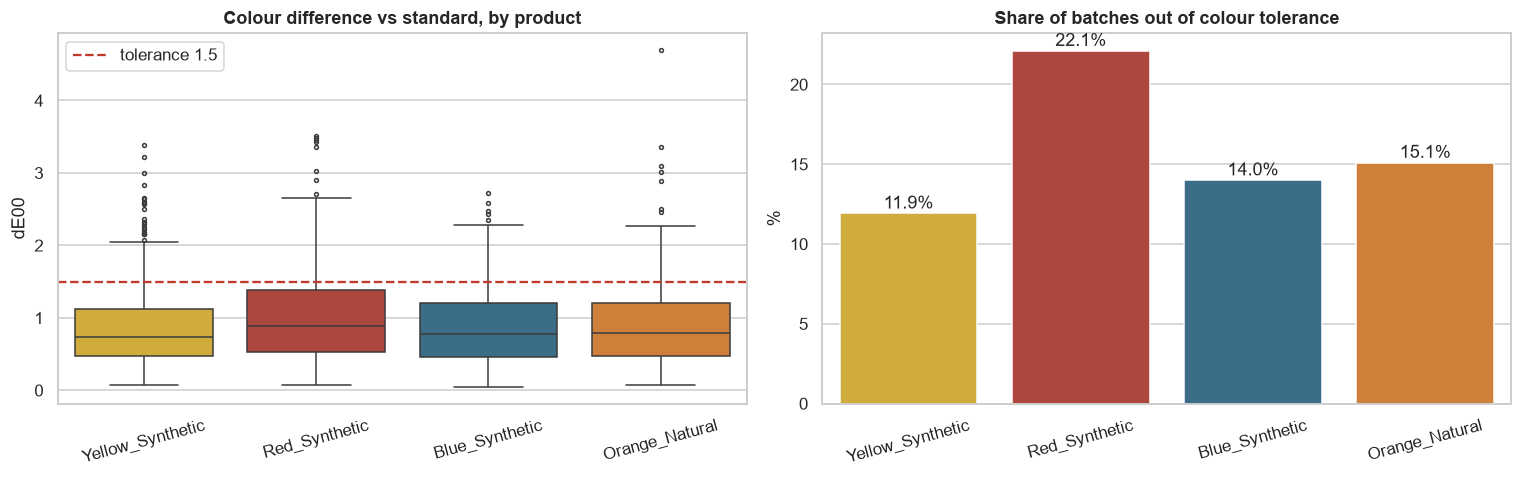

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = list(STANDARD_LAB)
sns.boxplot(data=df, x="Product", y="dE00", order=order, palette=PRODUCT_COLORS, hue="Product",
            legend=False, fliersize=2.5, ax=axes[0])
axes[0].axhline(SPEC["dE_max"], color=RED, ls="--", label=f"tolerance {SPEC['dE_max']}")
axes[0].set_title("Colour difference vs standard, by product"); axes[0].set_xlabel(""); axes[0].legend()
axes[0].tick_params(axis="x", rotation=15)

rate = df.groupby("Product")["is_oot"].mean().reindex(order) * 100
sns.barplot(x=rate.index, y=rate.values, palette=PRODUCT_COLORS, hue=rate.index, legend=False, ax=axes[1])
for i, v in enumerate(rate.values):
    axes[1].text(i, v + 0.3, f"{v:.1f}%", ha="center")
axes[1].set_title("Share of batches out of colour tolerance"); axes[1].set_ylabel("%"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()

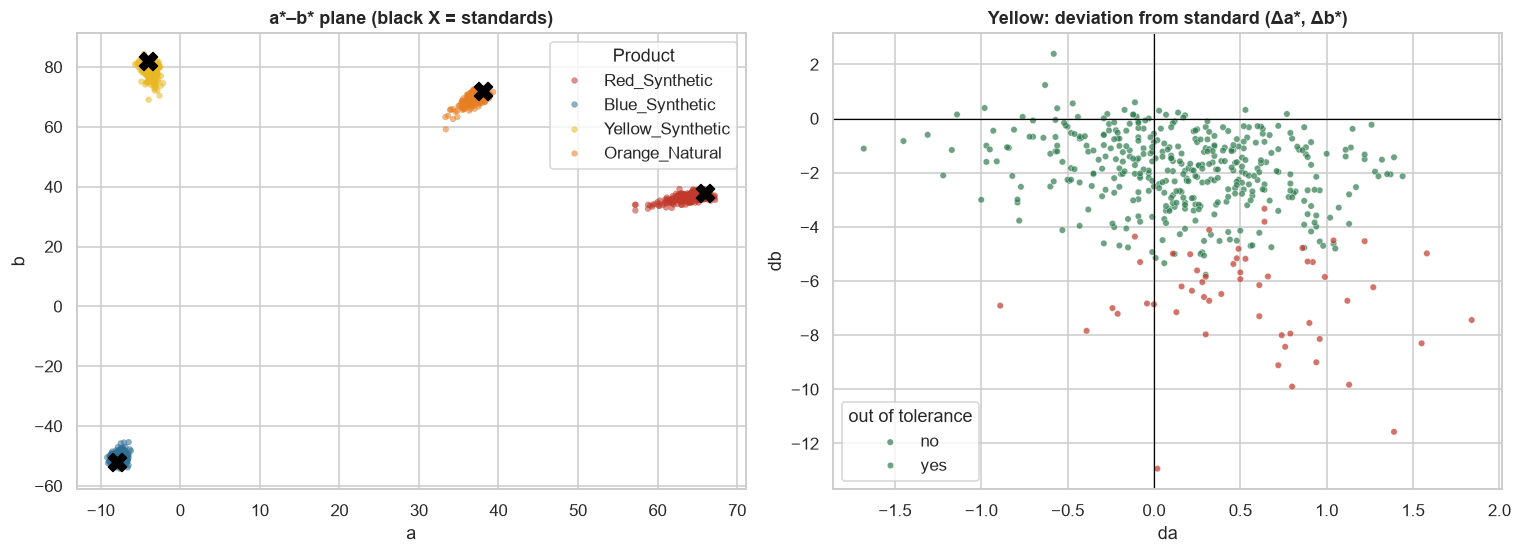

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.scatterplot(data=df, x="a", y="b", hue="Product", palette=PRODUCT_COLORS, s=14, alpha=0.55,
                edgecolor=None, ax=axes[0])
for p, (L, a, b) in STANDARD_LAB.items():
    axes[0].scatter(a, b, marker="X", s=140, color="black", zorder=5)
axes[0].set_title("a*–b* plane (black X = standards)")

sub = df[df["Product"] == "Yellow_Synthetic"]
sns.scatterplot(data=sub, x="da", y="db", hue="is_oot", palette={0.0: GREEN, 1.0: RED}, s=18, alpha=0.7, ax=axes[1])
axes[1].axhline(0, color="black", lw=0.8); axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Yellow: deviation from standard (Δa*, Δb*)")
axes[1].legend(title="out of tolerance", labels=["no", "yes"])
plt.tight_layout()

### Is there a supplier effect?

We use non-parametric tests because ΔE is bounded at zero and right-skewed.

Kruskal-Wallis (dE00 across suppliers): H = 327.6, p = 7.4e-72
Supplier C vs the others: P(C higher) = 0.814, p = 2.2e-73
Supplier C first used on: 2024-08-21


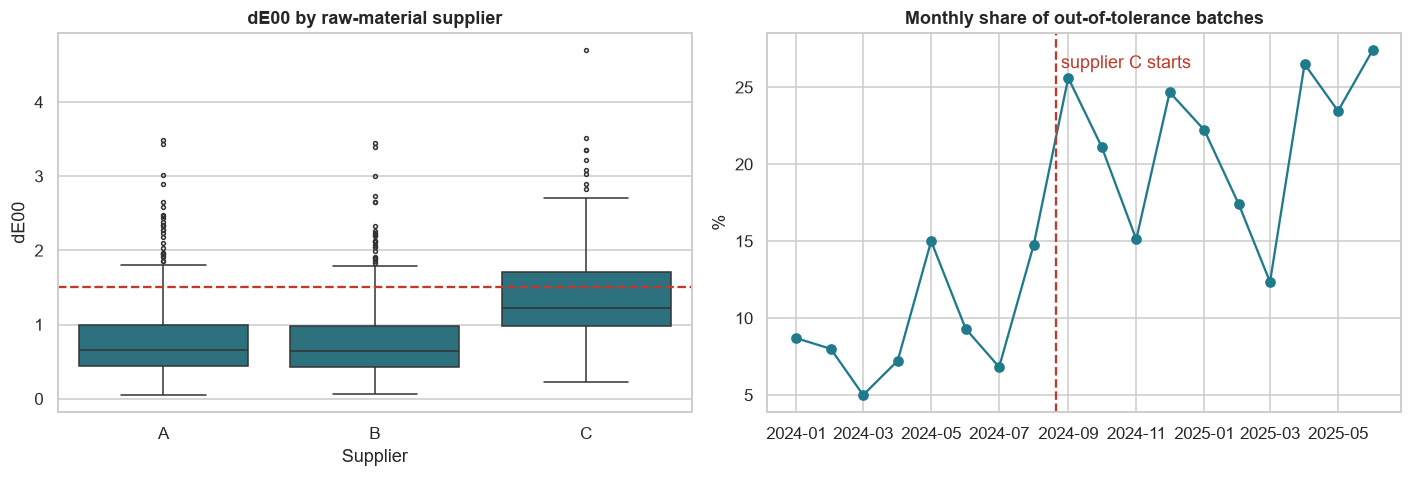

In [16]:
groups = [g["dE00"].dropna() for _, g in df.groupby("Supplier")]
h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis (dE00 across suppliers): H = {h:.1f}, p = {p:.1e}")

c = df.loc[df["Supplier"] == "C", "dE00"].dropna(); others = df.loc[df["Supplier"] != "C", "dE00"].dropna()
u, p2 = stats.mannwhitneyu(c, others, alternative="greater")
print(f"Supplier C vs the others: P(C higher) = {u / (len(c) * len(others)):.3f}, p = {p2:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="Supplier", y="dE00", color=TEAL, fliersize=2.5, ax=axes[0])
axes[0].axhline(SPEC["dE_max"], color=RED, ls="--"); axes[0].set_title("dE00 by raw-material supplier")

monthly = df.groupby(df["Date"].dt.to_period("M")).agg(oot=("is_oot", "mean"), n=("is_oot", "size"))
x = monthly.index.to_timestamp()
axes[1].plot(x, monthly["oot"] * 100, marker="o", color=TEAL)
c_start = df.loc[df["Supplier"] == "C", "Date"].min()
axes[1].axvline(c_start, color=RED, ls="--"); axes[1].text(c_start, axes[1].get_ylim()[1] * 0.92, " supplier C starts", color=RED)
axes[1].set_title("Monthly share of out-of-tolerance batches"); axes[1].set_ylabel("%")
plt.tight_layout()
print("Supplier C first used on:", c_start.date())

In [17]:
tab = pd.crosstab(df["Shift"], df["is_oot"].dropna().astype(int))
chi2, p_shift, _, _ = stats.chi2_contingency(tab)
print(f"Out-of-tolerance rate by shift (chi-square p = {p_shift:.1e}):")
print((df.groupby("Shift")["is_oot"].mean() * 100).round(1).to_string())
print("\nBy line:")
print((df.groupby("Line")["is_oot"].mean() * 100).round(1).to_string())

Out-of-tolerance rate by shift (chi-square p = 2.7e-06):
Shift
Afternoon    12.9
Morning      14.3
Night        26.0

By line:
Line
Line-1    14.9
Line-2    14.6
Line-3    19.2


## 6. Statistical process control

An **individuals (I) chart** shows whether the process is stable. Control limits come from a **baseline period** (before supplier C was introduced), using the average moving range (σ ≈ MR̄ / 1.128). Points outside ±3σ, or **8 consecutive points on one side of the centre line** (Nelson rule 2), signal a special cause.

Then the question that matters after a change: is the process still **capable** of meeting the spec?

,CL,UCL,LCL,sigma,% points signalling BEFORE change,% points signalling AFTER change
strength,99.27,103.57,94.97,1.43,1.67,6.29
dE00,0.80,2.25,0.00,0.48,4.71,9.50


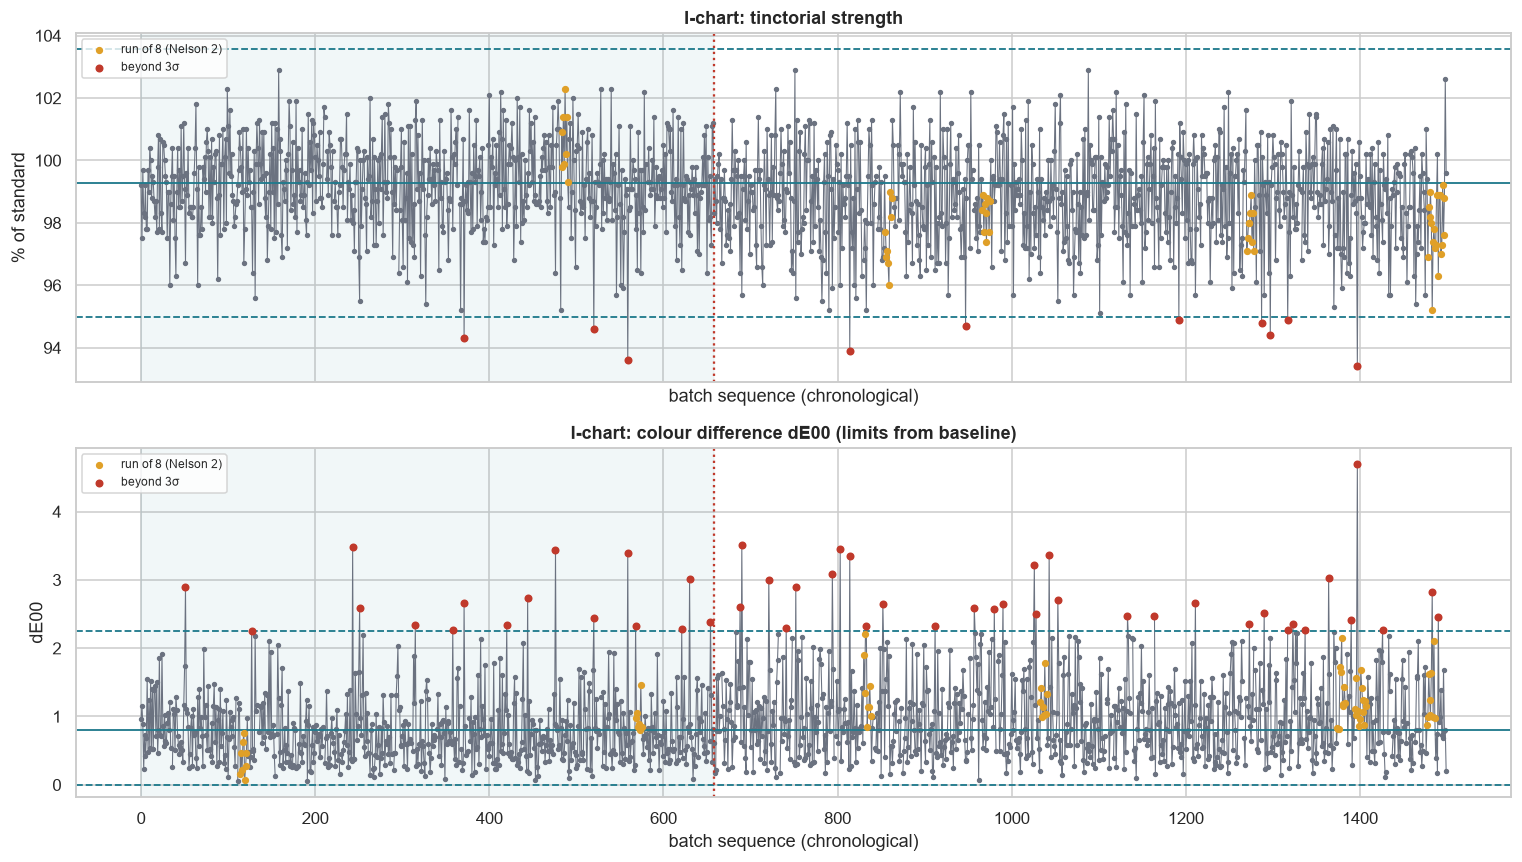

In [18]:
def run_flags(x, cl, n=8):
    """True for points that belong to a run of >= n consecutive points on the same side of the centre line."""
    side = np.sign(np.asarray(x) - cl)
    flags = np.zeros(len(side), dtype=bool)
    run, prev = 0, 0
    for i, s in enumerate(side):
        run = run + 1 if (s != 0 and s == prev) else (1 if s != 0 else 0)
        prev = s
        if run >= n:
            flags[i - n + 1:i + 1] = True
    return flags

def individuals_chart(ax, dates, x, baseline_mask, title, ylabel, lower_bound=None):
    x = pd.Series(np.asarray(x, dtype=float))
    mr = x.diff().abs()
    cl = x[baseline_mask].mean()
    sigma = mr[baseline_mask].mean() / 1.128
    ucl, lcl = cl + 3 * sigma, cl - 3 * sigma
    if lower_bound is not None:
        lcl = max(lcl, lower_bound)
    out = ((x > ucl) | (x < lcl)).to_numpy()
    runs = run_flags(x.fillna(cl).to_numpy(), cl)
    idx = np.arange(len(x))
    ax.plot(idx, x, color=GREY, lw=0.7, marker="o", ms=2.5, mfc=GREY, mec=GREY)
    ax.scatter(idx[runs & ~out], x[runs & ~out], color="#E0A028", s=14, zorder=3, label="run of 8 (Nelson 2)")
    ax.scatter(idx[out], x[out], color=RED, s=18, zorder=4, label="beyond 3σ")
    for v, ls, lab in [(cl, "-", "CL"), (ucl, "--", "UCL"), (lcl, "--", "LCL")]:
        ax.axhline(v, color=TEAL, ls=ls, lw=1.2)
    start = int(np.argmax(~baseline_mask.to_numpy()))
    ax.axvspan(0, start, color=TEAL, alpha=0.06); ax.axvline(start, color=RED, ls=":")
    ax.set_title(title); ax.set_ylabel(ylabel); ax.set_xlabel("batch sequence (chronological)")
    ax.legend(loc="upper left", fontsize=8)
    sig = out | runs
    base = baseline_mask.to_numpy()
    return {"CL": cl, "UCL": ucl, "LCL": lcl, "sigma": sigma,
            "% points signalling BEFORE change": sig[base].mean() * 100,
            "% points signalling AFTER change": sig[~base].mean() * 100}

baseline = df["Date"] < c_start               # phase I: before supplier C
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
r1 = individuals_chart(axes[0], df["Date"], df["Strength_pct"], baseline, "I-chart: tinctorial strength", "% of standard")
r2 = individuals_chart(axes[1], df["Date"], df["dE00"], baseline, "I-chart: colour difference dE00 (limits from baseline)", "dE00", lower_bound=0)
plt.tight_layout()
pd.DataFrame({"strength": r1, "dE00": r2}).T.round(2)

The shaded area is the baseline period used to compute the limits; the dotted red line is the introduction of supplier C. Compare **how many points signal before and after** that line (table above): a stable process raises only occasional false alarms, a shifted one signals constantly — that is how SPC detects a process change long before a monthly summary does.

*Caveat:* ΔE00 is bounded at zero and right-skewed, so its I-chart limits are approximate (some false alarms are expected even in the baseline); an EWMA chart or a transformed ΔE would be the next refinement.

In [19]:
def capability(x, lsl, usl):
    x = pd.Series(x).dropna()
    mu, sd = x.mean(), x.std(ddof=1)
    cp = (usl - lsl) / (6 * sd)
    cpk = min((usl - mu) / (3 * sd), (mu - lsl) / (3 * sd))
    obs_out = ((x < lsl) | (x > usl)).mean()
    return {"n": len(x), "mean": mu, "sd": sd, "Cp": cp, "Cpk": cpk, "observed out-of-spec %": obs_out * 100}

periods = {"before supplier C": df[df["Date"] < c_start], "after supplier C": df[df["Date"] >= c_start]}
cap = pd.DataFrame({k: capability(v["Strength_pct"], SPEC["strength_lo"], SPEC["strength_hi"]) for k, v in periods.items()}).T
print("Process capability of tinctorial strength (spec %.0f-%.0f%%):" % (SPEC["strength_lo"], SPEC["strength_hi"]))
cap.round(2)

Process capability of tinctorial strength (spec 95-105%):


,n,mean,sd,Cp,Cpk,observed out-of-spec %
before supplier C,652.0,99.27,1.38,1.20,1.03,0.46
after supplier C,834.0,98.78,1.53,1.09,0.82,0.84


In [20]:
sh = stats.shapiro(df["Strength_pct"].dropna().sample(500, random_state=RANDOM_STATE))
print(f"Normality check on 500 random strength values: Shapiro-Wilk p = {sh.pvalue:.3f} "
      f"({'consistent with normality' if sh.pvalue > 0.05 else 'NOT normal - interpret Cpk with care'})")
print("Rule of thumb: Cpk >= 1.33 is capable, 1.0-1.33 marginal, < 1.0 not capable.")

Normality check on 500 random strength values: Shapiro-Wilk p = 0.017 (NOT normal - interpret Cpk with care)
Rule of thumb: Cpk >= 1.33 is capable, 1.0-1.33 marginal, < 1.0 not capable.


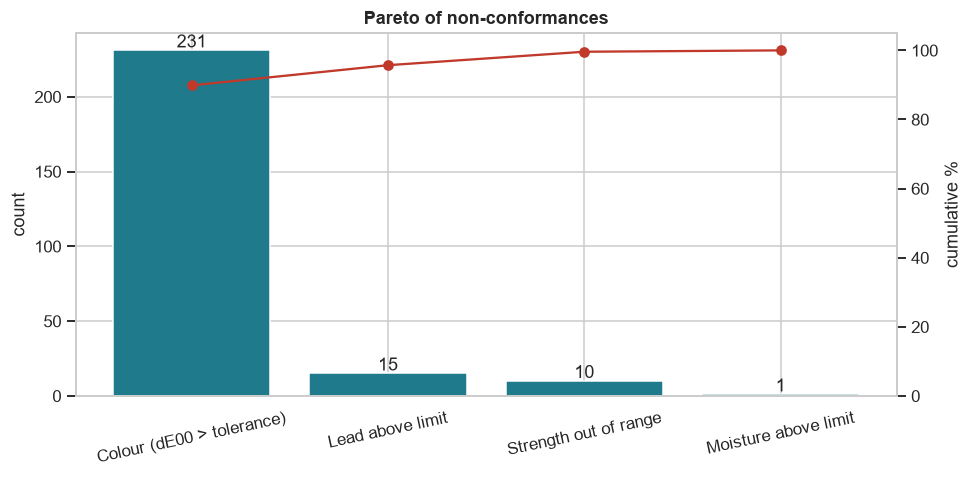

In [21]:
nc = pd.Series({"Colour (dE00 > tolerance)": df["nc_dE"].sum(), "Strength out of range": df["nc_strength"].sum(),
                "Moisture above limit": df["nc_moisture"].sum(), "Lead above limit": df["nc_lead"].sum()}).sort_values(ascending=False)
cum = nc.cumsum() / nc.sum() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(nc.index, nc.values, color=TEAL)
ax2 = ax.twinx(); ax2.plot(nc.index, cum.values, color=RED, marker="o"); ax2.set_ylim(0, 105); ax2.set_ylabel("cumulative %")
ax2.grid(False)
for i, v in enumerate(nc.values):
    ax.text(i, v + 2, int(v), ha="center")
ax.set_title("Pareto of non-conformances"); ax.tick_params(axis="x", rotation=12); ax.set_ylabel("count")
plt.tight_layout()

## 7. What drives colour deviation?

We build **process-based features** (all known at the end of the batch, *before* the lab result):

* `Temp_Dev` – reaction temperature minus the SOP target of that product (and `Over_Temp`, `Abs_Temp_Dev`),
* `pH_Dev` – final pH minus target,
* `Mix_Short` – minutes below the minimum mixing time,
* `Dry_Over` – drying temperature above the maximum (powders),
* `Is_Powder` – powder vs liquid.

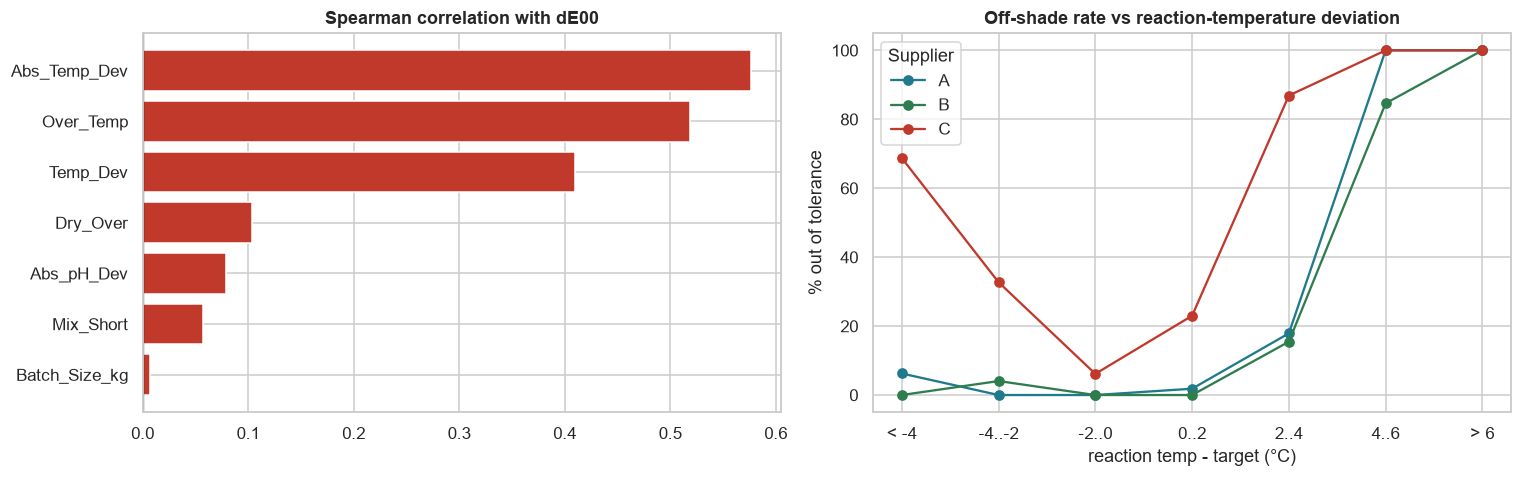

In [22]:
def add_process_features(d):
    d = d.copy()
    d["Temp_Dev"] = d["Reaction_Temp_C"] - d["Product"].map({k: v[0] for k, v in PROCESS_TARGETS.items()})
    d["pH_Dev"] = d["pH_Final"] - d["Product"].map({k: v[1] for k, v in PROCESS_TARGETS.items()})
    d["Abs_Temp_Dev"], d["Abs_pH_Dev"] = d["Temp_Dev"].abs(), d["pH_Dev"].abs()
    d["Over_Temp"] = d["Temp_Dev"].clip(lower=0)
    d["Mix_Short"] = (MIX_MIN_SOP - d["Mixing_Time_min"]).clip(lower=0)
    d["Is_Powder"] = (d["Form"] == "Powder").astype(int)
    d["Dry_Over"] = (d["Drying_Temp_C"] - DRY_MAX_SOP).clip(lower=0).fillna(0)
    return d

df_feat = add_process_features(df)
corr_cols = ["Temp_Dev", "Abs_Temp_Dev", "Over_Temp", "Abs_pH_Dev", "Mix_Short", "Dry_Over", "Batch_Size_kg"]
rho = df_feat[corr_cols].corrwith(df_feat["dE00"], method="spearman").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].barh(rho.index, rho.values, color=[RED if v > 0 else TEAL for v in rho.values])
axes[0].set_title("Spearman correlation with dE00"); axes[0].axvline(0, color="black", lw=0.8)

bins = [-np.inf, -4, -2, 0, 2, 4, 6, np.inf]
labels = ["< -4", "-4..-2", "-2..0", "0..2", "2..4", "4..6", "> 6"]
df_feat["Temp_bin"] = pd.cut(df_feat["Temp_Dev"], bins=bins, labels=labels)
piv = (df_feat.groupby(["Temp_bin", "Supplier"], observed=True)["is_oot"].mean().unstack() * 100)
piv.plot(marker="o", ax=axes[1], color={"A": TEAL, "B": GREEN, "C": RED})
axes[1].set_title("Off-shade rate vs reaction-temperature deviation"); axes[1].set_ylabel("% out of tolerance")
axes[1].set_xlabel("reaction temp - target (°C)")
plt.tight_layout()

Two things appear together: **overheating raises the off-shade rate**, and **supplier C shifts the whole curve upward** — i.e. both a process lever (temperature control) and a material lever (supplier qualification).

## 8. Early-warning models (process data → colour result)

**Goal:** tell the lab *which batches deserve priority attention* before (or without) the colour measurement.

**Design decisions that matter:**
* **Only process / material information is used as input.** L\*, a\*, b\*, strength and the release decision are *outcomes*; using them would make the model look perfect and be useless (data leakage).
* **Chronological split.** Production data drifts (here: a supplier change), so we train on the earlier 75% of batches and test on the latest 25%, and use `TimeSeriesSplit` for cross-validation — never a random shuffle.
* Imputation, scaling and one-hot encoding live inside the `Pipeline`, fitted on training data only.
* **A model can only learn about a supplier it has already seen.** Look at the share of supplier C in the training vs the test period printed below: if a new supplier appears only at the very end of training, the model has no idea how it behaves — in practice this is why such models must be monitored and retrained after a change.

In [23]:
CAT = ["Product", "Form", "Line", "Shift", "Supplier"]
NUM = ["Batch_Size_kg", "Reaction_Temp_C", "pH_Final", "Mixing_Time_min", "Drying_Temp_C", "Temp_Dev", "pH_Dev",
       "Abs_Temp_Dev", "Abs_pH_Dev", "Over_Temp", "Mix_Short", "Is_Powder", "Dry_Over"]
FEATURES = CAT + NUM
BASE_PROCESS_COLS = ["Product", "Form", "Line", "Shift", "Supplier", "Batch_Size_kg", "Reaction_Temp_C",
                     "pH_Final", "Mixing_Time_min", "Drying_Temp_C"]

dm = df_feat[df_feat["dE00"].notna()].sort_values(["Date", "Batch_ID"]).reset_index(drop=True)
cut = int(len(dm) * 0.75)
train, test = dm.iloc[:cut], dm.iloc[cut:]
X_train, X_test = train[FEATURES], test[FEATURES]
y_reg_train, y_reg_test = train["dE00"], test["dE00"]
y_clf_train, y_clf_test = train["is_oot"].astype(int), test["is_oot"].astype(int)

print(f"train: {len(train)} batches ({train['Date'].min().date()} -> {train['Date'].max().date()})")
print(f"test : {len(test)} batches ({test['Date'].min().date()} -> {test['Date'].max().date()})")
print("share of supplier C   train: %.1f%%   test: %.1f%%" % ((train['Supplier'] == 'C').mean() * 100, (test['Supplier'] == 'C').mean() * 100))
print("out-of-tolerance rate train: %.1f%%   test: %.1f%%" % (y_clf_train.mean() * 100, y_clf_test.mean() * 100))

def make_preprocessor():
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    return ColumnTransformer([("num", num, NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

def pipe(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

tscv = TimeSeriesSplit(n_splits=5)

train: 1093 batches (2024-01-01 -> 2025-02-10)
test : 365 batches (2025-02-11 -> 2025-06-30)
share of supplier C   train: 18.1%   test: 47.4%
out-of-tolerance rate train: 13.8%   test: 21.9%


### 8a. Regression — how large will ΔE00 be?

In [24]:
reg_models = {
    "Baseline (mean)": pipe(DummyRegressor()),
    "Ridge": pipe(Ridge(alpha=1.0)),
    "Random Forest": pipe(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1)),
    "Hist Gradient Boosting": pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
}
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
rows = []
for name, m in reg_models.items():
    r = cross_validate(m, X_train, y_reg_train, cv=tscv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, "MAE": -r["test_mae"].mean(), "RMSE": -r["test_rmse"].mean(), "R2": r["test_r2"].mean()})
reg_cv = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
best_reg_name = reg_cv[reg_cv["model"] != "Baseline (mean)"].iloc[0]["model"]
print("Time-series cross-validation on the training period:")
reg_cv.round(3)

Time-series cross-validation on the training period:


,model,MAE,RMSE,R2
0,Ridge,0.214,0.284,0.765
1,Random Forest,0.245,0.336,0.675
2,Hist Gradient Boosting,0.250,0.340,0.658
3,Baseline (mean),0.444,0.606,-0.048


MAE     0.205
RMSE    0.264
R2      0.814

Baseline MAE (always predict the training mean): 0.475


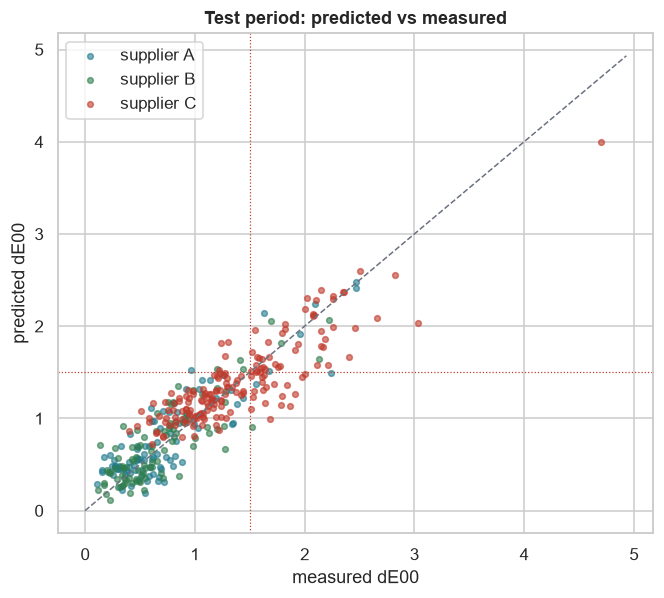

In [25]:
final_reg = clone(reg_models[best_reg_name]).fit(X_train, y_reg_train)
pred = final_reg.predict(X_test)
reg_test = pd.Series({"MAE": mean_absolute_error(y_reg_test, pred),
                      "RMSE": mean_squared_error(y_reg_test, pred) ** 0.5, "R2": r2_score(y_reg_test, pred)},
                     name=f"{best_reg_name} on the test period")
base_mae = mean_absolute_error(y_reg_test, np.full(len(y_reg_test), y_reg_train.mean()))
print(reg_test.round(3).to_string())
print(f"\nBaseline MAE (always predict the training mean): {base_mae:.3f}")

fig, ax = plt.subplots(figsize=(6.2, 5.6))
sc = {"A": TEAL, "B": GREEN, "C": RED}
for s, g in test.assign(pred=pred).groupby("Supplier"):
    ax.scatter(g["dE00"], g["pred"], s=14, alpha=0.6, color=sc[s], label=f"supplier {s}")
lim = max(test["dE00"].max(), pred.max()) * 1.05
ax.plot([0, lim], [0, lim], "--", color=GREY, lw=1)
ax.axhline(SPEC["dE_max"], color=RED, lw=0.8, ls=":"); ax.axvline(SPEC["dE_max"], color=RED, lw=0.8, ls=":")
ax.set_xlabel("measured dE00"); ax.set_ylabel("predicted dE00"); ax.set_title("Test period: predicted vs measured"); ax.legend()
plt.tight_layout()

### 8b. Classification — will this batch be out of tolerance?

Only a minority of batches are off-shade (the rate is printed below), so **accuracy is misleading** — always answering "fine" would look accurate. We judge models by **PR-AUC** (baseline = the off-shade rate) and **ROC-AUC**.

In [26]:
clf_models = {
    "Baseline (prior)": pipe(DummyClassifier(strategy="prior")),
    "Logistic Regression": pipe(LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                                 random_state=RANDOM_STATE, n_jobs=-1)),
    "Hist Gradient Boosting": pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
}
rows = []
for name, m in clf_models.items():
    r = cross_validate(m, X_train, y_clf_train, cv=tscv, scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, n_jobs=-1)
    rows.append({"model": name, "PR-AUC": r["test_pr_auc"].mean(), "ROC-AUC": r["test_roc_auc"].mean()})
clf_cv = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
best_clf_name = clf_cv[clf_cv["model"] != "Baseline (prior)"].iloc[0]["model"]
print("Time-series cross-validation (PR-AUC of a useless model = off-shade rate = %.3f):" % y_clf_train.mean())
clf_cv.round(3)

Time-series cross-validation (PR-AUC of a useless model = off-shade rate = 0.138):


,model,PR-AUC,ROC-AUC
0,Random Forest,0.830,0.934
1,Logistic Regression,0.823,0.949
2,Hist Gradient Boosting,0.749,0.927
3,Baseline (prior),0.151,0.500


In [27]:
param_spaces = {
    "Logistic Regression": {"model__C": np.logspace(-2, 2, 20)},
    "Random Forest": {"model__max_depth": [None, 6, 10, 16], "model__min_samples_leaf": [1, 3, 5, 10],
                      "model__max_features": ["sqrt", 0.5]},
    "Hist Gradient Boosting": {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_leaf_nodes": [8, 15, 31],
                               "model__min_samples_leaf": [10, 20, 40], "model__l2_regularization": [0, 0.1, 1.0]},
}
search = RandomizedSearchCV(clf_models[best_clf_name], param_spaces[best_clf_name], n_iter=10,
                            scoring="average_precision", cv=TimeSeriesSplit(n_splits=3),
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_clf_train)
best_clf = search.best_estimator_
best_params = {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
               for k, v in search.best_params_.items()}
print("Selected:", best_clf_name, "| tuned CV PR-AUC: %.3f" % search.best_score_)
print("Best parameters:", best_params)

Selected: Random Forest | tuned CV PR-AUC: 0.810
Best parameters: {'min_samples_leaf': 3, 'max_features': 'sqrt', 'max_depth': 6}


### Choosing the alert threshold without touching the test set

The last 20% of the training period is used as a **validation window**: we fit on the earlier part, and pick the highest probability threshold that still catches **at least 80% of the off-shade batches**. Then we refit on the full training period and evaluate once on the test period.

**Expect the test recall to differ from the 80% target.** The process drifted between the validation window and the test period (more supplier C), so a threshold tuned on the past does not transfer perfectly — which is exactly why alert thresholds must be re-checked after any process or supplier change.

In [28]:
TARGET_RECALL = 0.80
k = int(len(X_train) * 0.8)
tmp = clone(best_clf).fit(X_train.iloc[:k], y_clf_train.iloc[:k])
p_val = tmp.predict_proba(X_train.iloc[k:])[:, 1]
prec, rec, thr = precision_recall_curve(y_clf_train.iloc[k:], p_val)
ok_idx = np.where(rec[:-1] >= TARGET_RECALL)[0]
threshold = float(thr[ok_idx[-1]]) if len(ok_idx) else 0.5
print(f"Alert threshold chosen on the validation window: {threshold:.3f}")

final_clf = clone(best_clf).fit(X_train, y_clf_train)
p_test = final_clf.predict_proba(X_test)[:, 1]
flag = p_test >= threshold
tn, fp, fn, tp = confusion_matrix(y_clf_test, flag, labels=[0, 1]).ravel()
prevalence = y_clf_test.mean()

result = pd.Series({
    "PR-AUC (test)": average_precision_score(y_clf_test, p_test),
    "ROC-AUC (test)": roc_auc_score(y_clf_test, p_test),
    "off-shade rate in test (PR-AUC of a useless model)": prevalence,
    "recall at threshold": tp / (tp + fn),
    "precision at threshold": tp / (tp + fp) if (tp + fp) else np.nan,
    "share of batches flagged for priority check": flag.mean(),
    "lift (precision / base rate)": (tp / (tp + fp)) / prevalence if (tp + fp) else np.nan,
}, name=best_clf_name)
result.round(3)

Alert threshold chosen on the validation window: 0.520


PR-AUC (test)                                         0.814
ROC-AUC (test)                                        0.928
off-shade rate in test (PR-AUC of a useless model)    0.219
recall at threshold                                   0.688
precision at threshold                                0.786
share of batches flagged for priority check           0.192
lift (precision / base rate)                          3.585
Name: Random Forest, dtype: float64

,inspect top,off-shade batches caught
0,10%,40%
1,20%,70%
2,30%,81%
3,50%,98%


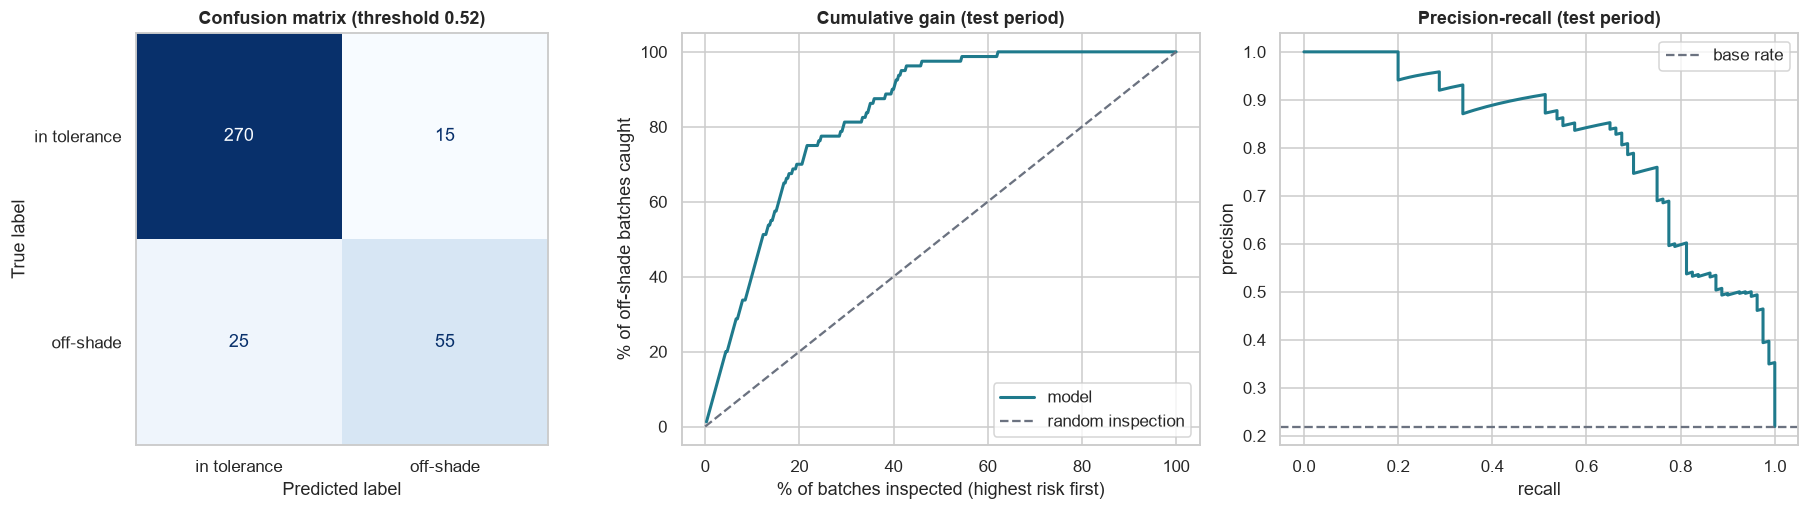

In [29]:
order_idx = np.argsort(-p_test)
gains = np.cumsum(y_clf_test.to_numpy()[order_idx]) / y_clf_test.sum()
frac = np.arange(1, len(p_test) + 1) / len(p_test)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_clf_test, flag, display_labels=["in tolerance", "off-shade"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Confusion matrix (threshold {threshold:.2f})"); axes[0].grid(False)

axes[1].plot(frac * 100, gains * 100, color=TEAL, lw=2, label="model")
axes[1].plot([0, 100], [0, 100], "--", color=GREY, label="random inspection")
axes[1].set_xlabel("% of batches inspected (highest risk first)"); axes[1].set_ylabel("% of off-shade batches caught")
axes[1].set_title("Cumulative gain (test period)"); axes[1].legend()

pr, rc, _ = precision_recall_curve(y_clf_test, p_test)
axes[2].plot(rc, pr, color=TEAL, lw=2); axes[2].axhline(prevalence, color=GREY, ls="--", label="base rate")
axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision-recall (test period)"); axes[2].legend()
plt.tight_layout()

pd.DataFrame({"inspect top": ["10%", "20%", "30%", "50%"],
              "off-shade batches caught": [f"{gains[int(len(gains) * q) - 1]:.0%}" for q in (0.1, 0.2, 0.3, 0.5)]})

### What did the model learn?

Top drivers: ['Supplier', 'Over_Temp', 'Abs_Temp_Dev', 'Temp_Dev']
Several features describe the same physical lever (e.g. Reaction_Temp_C, Temp_Dev, Over_Temp), so their importance is shared - read them as a group.


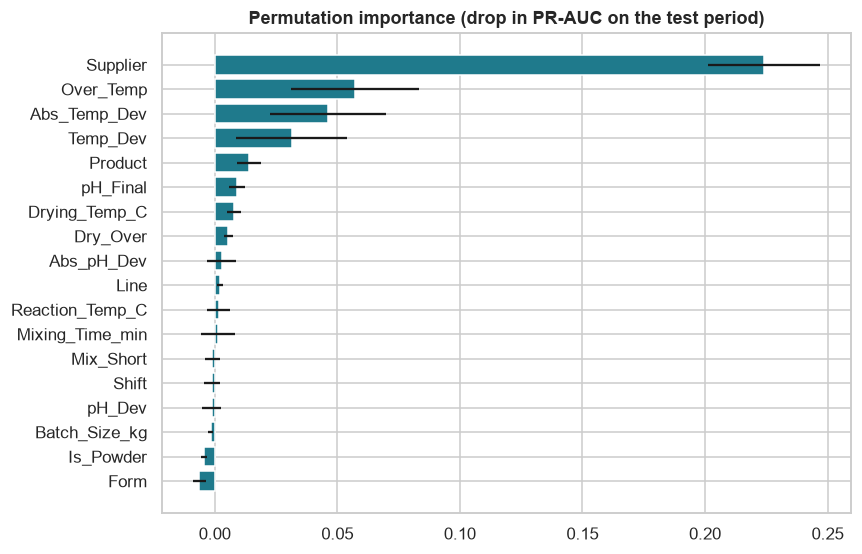

In [30]:
perm = permutation_importance(final_clf, X_test, y_clf_test, scoring="average_precision", n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"feature": FEATURES, "importance": perm.importances_mean, "std": perm.importances_std}) \
        .sort_values("importance")
imp = imp[imp["importance"].abs() > 1e-4]

plt.figure(figsize=(8, 5.2))
plt.barh(imp["feature"], imp["importance"], xerr=imp["std"], color=TEAL)
plt.title("Permutation importance (drop in PR-AUC on the test period)")
plt.tight_layout()
print("Top drivers:", imp.sort_values("importance", ascending=False)["feature"].head(4).tolist())
print("Several features describe the same physical lever (e.g. Reaction_Temp_C, Temp_Dev, Over_Temp), "
      "so their importance is shared - read them as a group.")

## 9. Save the model and score new batches

In [31]:
import os
os.makedirs("models", exist_ok=True)
joblib.dump({"classifier": final_clf, "regressor": final_reg, "features": FEATURES, "threshold": threshold,
             "spec": SPEC, "process_targets": PROCESS_TARGETS}, "models/colorant_early_warning.joblib")

def predict_batch(batch, threshold=threshold):
    """batch: dict with the process / material fields in BASE_PROCESS_COLS."""
    row = add_process_features(pd.DataFrame([batch]))[FEATURES]
    p = float(final_clf.predict_proba(row)[0, 1])
    return {"P(off-shade)": round(p, 3), "expected dE00": round(float(final_reg.predict(row)[0]), 2),
            "action": "PRIORITY LAB CHECK" if p >= threshold else "routine sampling"}

idx = test.index[:6]
demo = test.loc[idx, BASE_PROCESS_COLS].to_dict("records")
out = pd.DataFrame([predict_batch(b) for b in demo], index=test.loc[idx, "Batch_ID"])
out["measured dE00"] = test.loc[idx, "dE00"].round(2).values
out

,P(off-shade),expected dE00,action,measured dE00
Batch_ID,,,,
CL25122,0.435,1.28,routine sampling,1.09
CL25123,0.329,1.25,routine sampling,1.42
CL25124,0.137,0.95,routine sampling,0.85
CL25126,0.357,1.31,routine sampling,1.23
CL25127,0.292,1.09,routine sampling,0.75
CL25128,0.230,1.13,routine sampling,1.12


## 10. Summary

In [32]:
print("DATA")
print(f"  raw rows: {len(raw)} -> clean batches: {len(df)}   | batches with a colour result: {int(df['dE00'].notna().sum())}")
print(f"  out of colour tolerance (dE00 > {SPEC['dE_max']}): {df['is_oot'].mean():.1%}")
print(f"  recorded decisions that disagree with the spec rules: {int((complete & (df['rule_decision'] != df['Release_Decision'])).sum())} "
      f"(released although rules say rework/reject: {len(risky)})")
print("\nPROCESS")
print(f"  supplier C first used {c_start.date()}; median dE00  A/B: "
      f"{df.loc[df['Supplier'] != 'C', 'dE00'].median():.2f}   C: {df.loc[df['Supplier'] == 'C', 'dE00'].median():.2f}")
print(f"  strength Cpk  before: {cap.loc['before supplier C', 'Cpk']:.2f}   after: {cap.loc['after supplier C', 'Cpk']:.2f}")
print("\nEARLY-WARNING MODEL (time-ordered test period)")
print(f"  regression: {best_reg_name}, MAE {reg_test['MAE']:.2f} dE00 (baseline {base_mae:.2f})")
print(f"  classification: {best_clf_name}, PR-AUC {result['PR-AUC (test)']:.2f} (useless model: {prevalence:.2f})")
print(f"  flagging {flag.mean():.0%} of batches catches {result['recall at threshold']:.0%} of the off-shade ones")

DATA
  raw rows: 1519 -> clean batches: 1500   | batches with a colour result: 1458
  out of colour tolerance (dE00 > 1.5): 15.8%
  recorded decisions that disagree with the spec rules: 35 (released although rules say rework/reject: 3)

PROCESS
  supplier C first used 2024-08-21; median dE00  A/B: 0.65   C: 1.22
  strength Cpk  before: 1.03   after: 0.82

EARLY-WARNING MODEL (time-ordered test period)
  regression: Ridge, MAE 0.21 dE00 (baseline 0.48)
  classification: Random Forest, PR-AUC 0.81 (useless model: 0.22)
  flagging 19% of batches catches 69% of the off-shade ones


### Limitations and next steps
* **Simulated data.** Everything here describes a simulated process whose effects were built in; the point of the notebook is the *workflow*. Re-run it on your own anonymised export before drawing any plant conclusion.
* Specs, standards and process targets are **illustrative**; ΔE tolerances should come from the customer specification.
* The 80% recall target is a **business choice**: weigh the cost of a missed off-shade batch against the extra lab workload.
* Cpk assumes an approximately normal, stable process — check the control chart before quoting a capability index.
* Ideas to extend: EWMA / CUSUM charts for small shifts, change-point detection for the supplier switch, multivariate SPC (Hotelling T²) on L\*a\*b\*, a shade-correction recommender (which dosing change reduces ΔL\*/Δb\*), and a small Streamlit app around `predict_batch`.